# Function 6 · Week 10 cohort advice

The official x5 = 0 face remains competitive. The 2024 data identify a distinct interior region around x5 ≈ 0.11. A shortlist winner on the face leaves that regional question open.

## Expectations

Use the official accumulated observations to fit a Gaussian process in raw score units. For Function 1, a stable official positive-source fit supplies the mean function and the GP adjusts the residuals. Expected improvement (EI) is the expected positive difference between one future return and the official incumbent. The acquisition uses the GP's predictive observation uncertainty. The fitted GP supplies the same uncertainty to both advisers.

The official model screens a seeded Sobol pool across the domain and around high official points. The frozen shortlist includes the leading EI candidates, candidates from different search regions and coordinate directions, and the previous owner-first proposal when eligible. Official inputs and prior submissions are excluded at portal precision. Function 5 retains its 0.02 spacing rule.

Current-cohort returns and the 2024 archive fit **separate residual GPs**. Each learns the difference between its reported score and the official GP prediction. Repeated inputs contribute their median and their measured spread. Official coordinates are excluded from each adviser, including during replay. When a coordinate occurs in both external groups, the current cohort supplies the evidence at that coordinate. The 2024 source includes its extra starters and archived returns.

An adviser's residual adjusts the owner mean for its own EI calculation. Divide the resulting change in EI by the best owner EI and cap it at ±1. The ranking is **0.80 × normalised owner EI + 0.10 × current change + 0.10 × archival change**. A point with no nearby external support gets little adjustment. Weights are fixed judgement calls. The weight sweep shows their effect, including the official-only decision. This is a bounded shortlist adviser inspired by transfer Bayesian optimisation. [Transfer Bayesian optimisation](https://arxiv.org/abs/1802.02219)

## Results

The input fingerprints identify the local files reproduced below. The extended sources provide comparison and advice for this experiment. Course permission to rely on those scores for an assessed submission remains unresolved. [Course data-use review](../../../docs/capstone-data-policy.md) · [2024 intake and transfer review](../../../side-quests/historical-cohort-2024/README.md) · [Official weekly notebook](weekly_review.ipynb)

In [1]:
function = 6

from pathlib import Path
import json
import sys

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display

here = Path.cwd().resolve()
stage = next(path for path in (here, *here.parents) if (path / "notebooks/Shared").is_dir())
sys.path[:0] = [str(stage / "notebooks/Shared"),
                str(stage / "notebooks/Function_1/FunctionSpecificShared")]

from cohort_advisory_bo import SETTINGS, WEIGHTS, load_data, review
from cohort_advisory_plots import pairwise_slice
from weekly_peak_review import portal_point

owner, current, archive, columns, fingerprints = load_data(stage, function)
result = review(stage, function, owner, current, archive, columns)
print(f"{len(owner)} official rows, {result['pool_size']:,} eligible candidates, "
      f"{len(result['table'])} on the frozen shortlist.")
display(pd.Series(fingerprints, name="Intake evidence").to_frame())
display(result["comparison"].round(6))

29 official rows, 8,741 eligible candidates, 29 on the frozen shortlist.


,Intake evidence
Current intake date,2026-11-25
Archive revision,27e7ed89734766f89ae23af1871deebb34f3bca4
Official SHA-256,0effd9de967037c35ff77d2ca8affc7a69e43da342b656...
Current SHA-256,548e3dd811e8d22e0dc4804ce9e9b3ab617a9c7c1f3780...
2024 SHA-256,4d61b7878903cc5e70bc24dae1abee96863b6f4ce7f5e7...
2024 out-of-bounds rows excluded,0


,Source,Supplied rows,Used rows,Used coordinates,Best observed,Best observed input,Distance to nearest shortlist point,Nearest shortlist point,Nearest point ensemble rank
0,Current cohort,31,30,30,-0.204982,0.454330-0.363869-0.508315-0.757164-0.150167,0.170411,0.482160-0.343001-0.578528-0.775869-0.000000,10
1,2024 archive,106,105,103,-0.006144,0.424197-0.368357-0.648904-0.762441-0.113934,0.134272,0.492987-0.317649-0.662369-0.768273-0.011414,5


### Replay on the nine official returns

Remove each returned coordinate from official training in turn and refit. The external snapshots are frozen at their current versions and exclude every official coordinate. The replay measures **score prediction** retrospectively. It uses neither the historical information timeline nor a live optimisation experiment, so a lower replay error alone gives limited evidence about the next query. The 10% columns apply each advisory mean shift at the declared weight.

In [2]:
replay = result["replay"]
methods = ["Official only", "Current only", "2024 only", "10% each"]
error = replay[methods].sub(replay["Actual"], axis=0)
metrics = pd.DataFrame({"MAE": error.abs().mean(), "RMSE": error.pow(2).mean().pow(.5)})
display(metrics.round(8))
display(replay.round(8))
if result["structural"] is not None:
    fit = result["structural"]
    print(f"Official quadratic maximum: {fit['predicted_maximum']:.10g}, "
          f"maximum absolute replay error: {fit['later_max_abs_error']:.3g}.")

,MAE,RMSE
Official only,0.131726,0.179760
Current only,0.131353,0.177467
2024 only,0.126524,0.176901
10% each,0.126151,0.174594


,Round,Actual,Official only,Current only,2024 only,10% each,Owner latent SD
0,1,-0.378691,-0.479038,-0.478290,-0.463992,-0.463243,0.067075
1,2,-1.124281,-0.798759,-0.800877,-0.807338,-0.809456,0.314924
2,3,-0.551379,-0.595773,-0.610876,-0.600319,-0.615422,0.168187
3,4,-0.917070,-0.542885,-0.550042,-0.542064,-0.549221,0.188197
4,5,-0.651572,-0.547030,-0.550111,-0.552585,-0.555666,0.145861
5,6,-0.328192,-0.212231,-0.220410,-0.206728,-0.214907,0.025299
6,7,-0.213960,-0.303006,-0.304766,-0.293053,-0.294814,0.030070
7,8,-0.228584,-0.245304,-0.246243,-0.234931,-0.235870,0.069362
8,9,-0.241346,-0.256167,-0.256290,-0.247980,-0.248104,0.055469


## Predictions

Compare the official choice, the prior proposal and the bounded ensemble. A local alternative is shown when the wider shortlist wins. For F8 the verified official quadratic takes precedence over the ranking.

In [3]:
weight_rows = pd.DataFrame(WEIGHTS, index=["Official", "Current", "2024"]).T
display(weight_rows.assign(Input=pd.Series(result["winners"])))
table = result["table"]
front = [result["chosen"], result["winners"]["Official only"], result["previous"], result["local_winner"]]
candidates = table[table["Input"].isin(front)].copy()
candidates.insert(0, "Ensemble rank", candidates.index + 1)
display(candidates.round(7))
display(table.round(7))

,Official,Current,2024,Input
Official only,1.0,0.00,0.00,0.501822-0.322751-0.620839-0.821879-0.000000
Current only,0.9,0.10,0.00,0.501822-0.322751-0.620839-0.821879-0.000000
2024 only,0.9,0.00,0.10,0.496857-0.309192-0.625685-0.791371-0.000000
5% each,0.9,0.05,0.05,0.501822-0.322751-0.620839-0.821879-0.000000
10% each,0.8,0.10,0.10,0.496857-0.309192-0.625685-0.791371-0.000000


,Ensemble rank,Input,Owner mean,Owner return SD,Within owner radius,Owner EI,Current shift (y),2024 shift (y),Current score contribution,2024 score contribution,Official only,Current only,2024 only,5% each,10% each
0,1,0.496857-0.309192-0.625685-0.791371-0.000000,-0.200175,0.078412,False,0.038656,-0.081271,0.040675,-0.074844,0.067194,0.958098,0.787444,0.929482,0.858463,0.758828
2,3,0.501822-0.322751-0.620839-0.821879-0.000000,-0.202587,0.086132,False,0.040347,-0.102519,0.017202,-0.084100,0.025221,1.000000,0.815900,0.925221,0.870560,0.741121
3,4,0.487509-0.299127-0.661382-0.768313-0.000000,-0.204686,0.075742,True,0.035079,-0.066100,0.063410,-0.062332,0.100000,0.869436,0.720161,0.882493,0.801327,0.733217
28,29,0.528534-0.395701-0.607892-0.792820-0.038603,-0.248672,0.092977,False,0.022292,-0.055300,0.030021,-0.034856,0.030987,0.552505,0.462398,0.528241,0.495320,0.438135


,Input,Owner mean,Owner return SD,Within owner radius,Owner EI,Current shift (y),2024 shift (y),Current score contribution,2024 score contribution,Official only,Current only,2024 only,5% each,10% each
0,0.496857-0.309192-0.625685-0.791371-0.000000,-0.200175,0.078412,False,0.038656,-0.081271,0.040675,-0.074844,0.067194,0.958098,0.787444,0.929482,0.858463,0.758828
1,0.490442-0.351466-0.680659-0.803998-0.000000,-0.208347,0.088590,False,0.038219,-0.073378,0.040226,-0.066662,0.061145,0.947268,0.785879,0.913687,0.849783,0.752298
2,0.501822-0.322751-0.620839-0.821879-0.000000,-0.202587,0.086132,False,0.040347,-0.102519,0.017202,-0.084100,0.025221,1.000000,0.815900,0.925221,0.870560,0.741121
3,0.487509-0.299127-0.661382-0.768313-0.000000,-0.204686,0.075742,True,0.035079,-0.066100,0.063410,-0.062332,0.100000,0.869436,0.720161,0.882493,0.801327,0.733217
4,0.492987-0.317649-0.662369-0.768273-0.011414,-0.206972,0.077152,False,0.034399,-0.060056,0.070254,-0.057370,0.100000,0.852579,0.709951,0.867321,0.788636,0.724693
5,0.506842-0.300810-0.643944-0.757009-0.000000,-0.208540,0.078882,False,0.034254,-0.065245,0.056895,-0.059624,0.093470,0.848975,0.704454,0.857548,0.781001,0.713026
6,0.501816-0.297155-0.627511-0.751342-0.000000,-0.207179,0.075481,True,0.033624,-0.062471,0.058318,-0.058278,0.098126,0.833369,0.691754,0.848158,0.769956,0.706543
7,0.509374-0.359493-0.667404-0.778227-0.000000,-0.213916,0.087628,False,0.034980,-0.063668,0.045987,-0.057015,0.068676,0.866980,0.723267,0.848958,0.786113,0.705246
8,0.520422-0.310712-0.615576-0.808687-0.000000,-0.210264,0.089142,False,0.037441,-0.099597,0.016175,-0.076898,0.022151,0.927977,0.758281,0.857329,0.807805,0.687634
9,0.482160-0.343001-0.578528-0.775869-0.000000,-0.202715,0.070513,False,0.034110,-0.071625,0.039141,-0.065538,0.064700,0.845405,0.695326,0.825564,0.760445,0.675485


### Prepared Week 10 decision

**Prepared and unsubmitted as of 25 November 2026.** Round 9 is the latest confirmed feedback. Four portal queries remain per function, including Week 10. Use the cohort-informed route only if the course permits that use, including the exact published F2 repeat. The official-data fallback is ready if the rules remain unclear near the portal deadline.

The revised input is the centroid of four strong archived interior points from one reporting ID. Their outputs range from −0.065 to −0.006. The bounded advisory ranking and the official-data fallback keep x5=0, where the official evidence is concentrated. This is a deliberate transfer test outside the shortlist, with one participant supplying the tight cluster.

**Week 11 depends on the return.** Refine the interior only after a competitive official return. A weak result favours the confirmed face for the next query.

[Week 10 course check and exact batches](../../../submissions/Week_10/README.md) · [Cohort advice and replay](../../../submissions/Week_10/advisory-review.md)

The estimates below use the advisory review's official-data GP comparator and predictive return standard deviation, which includes modelled observation noise. F8 uses the validated starter quadratic and omits a standard deviation because that fit supplies no probabilistic interval. The rows are proposed inputs with model estimates.

In [4]:
from week_10_decision_record import decision_comparison

with pd.option_context("display.max_colwidth", None):
    display(decision_comparison(stage, function, owner, result["model"], result["structural"]))

,Portal input,Official GP mean (score),Predictive return SD
Stage,,,
Initial proposal,0.436425-0.308543-0.611598-0.707302-0.000000,-0.233849,0.056020
Advisory experiment,0.496857-0.309192-0.625685-0.791371-0.000000,-0.200175,0.078412
Revised cohort-informed,0.415446-0.370229-0.652604-0.763869-0.109806,-0.290461,0.078237
Official-data fallback,0.477724-0.315120-0.640574-0.732989-0.000000,-0.207383,0.065922


### Pairwise fitted surfaces

For each pair, hold the other coordinates at the advisory experiment's winner. The star marks that acquisition winner. The circle projects the incumbent and the plus projects the best archived point. These reference markers may come from a different slice. The top-right panel shows the owner GP's latent uncertainty. For F8 this is the uncertainty of the GP comparator, while the mean panel shows the verified quadratic. Lower panels show the two signed adjustments to the GP mean in raw output units using the same colour scale within each figure. The capped acquisition contributions appear in the shortlist table.

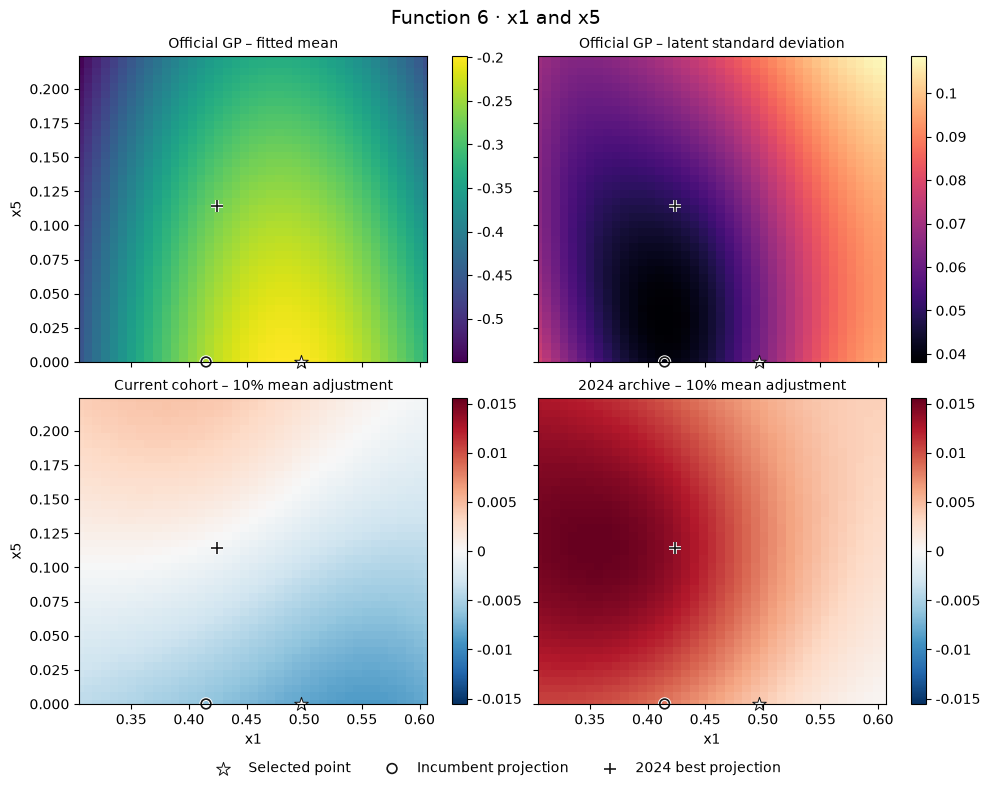

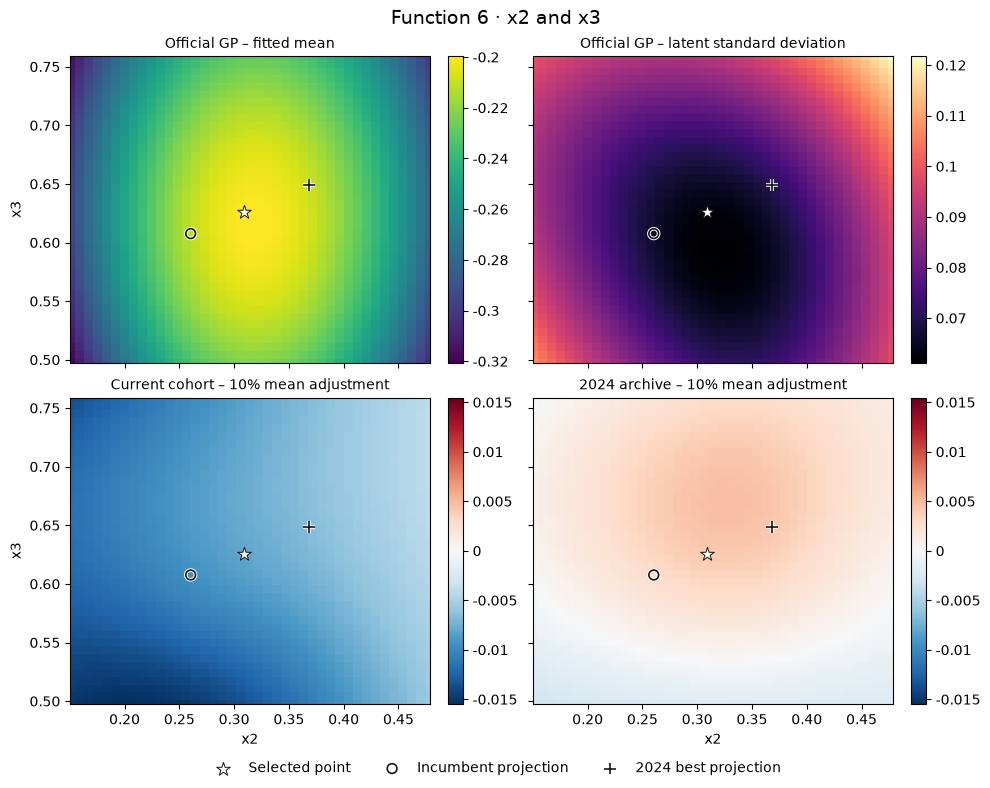

In [5]:
for pair in SETTINGS[function][4]:
    figure = pairwise_slice(function, result, pair)
    plt.show()
    plt.close(figure)

In [6]:
summary = {
    "function": function,
    "incumbent": portal_point(result["incumbent"]),
    "incumbent_y": result["incumbent_y"],
    "selected": result["chosen"],
    "official_only": result["winners"]["Official only"],
    "older_proposal": result["previous"],
    "local": result["local_winner"],
    "weight_sweep": result["winners"],
    "selected_in_radius": bool(table.loc[table["Input"].eq(result["chosen"]), "Within owner radius"].iloc[0]),
    "mae_official": float(metrics.loc["Official only", "MAE"]),
    "mae_advisory": float(metrics.loc["10% each", "MAE"]),
    "closest_2024_best": float(result["comparison"].loc[1, "Distance to nearest shortlist point"]),
}
print(json.dumps(summary, allow_nan=False))

{"function": 6, "incumbent": "0.414821-0.260324-0.607614-0.728412-0.000000", "incumbent_y": -0.2139595403345748, "selected": "0.496857-0.309192-0.625685-0.791371-0.000000", "official_only": "0.501822-0.322751-0.620839-0.821879-0.000000", "older_proposal": "0.528534-0.395701-0.607892-0.792820-0.038603", "local": "0.487509-0.299127-0.661382-0.768313-0.000000", "weight_sweep": {"Official only": "0.501822-0.322751-0.620839-0.821879-0.000000", "Current only": "0.501822-0.322751-0.620839-0.821879-0.000000", "2024 only": "0.496857-0.309192-0.625685-0.791371-0.000000", "5% each": "0.501822-0.322751-0.620839-0.821879-0.000000", "10% each": "0.496857-0.309192-0.625685-0.791371-0.000000"}, "selected_in_radius": false, "mae_official": 0.13172645386104326, "mae_advisory": 0.12615093018666595, "closest_2024_best": 0.13427223917474526}


### Course workflow

1. **Define the goal and scope** – improve the best future official score with four queries remaining, including Week 10.
2. **Gather the data** – verify the official, current-cohort and 2024 snapshot fingerprints.
3. **Explore the data** – compare the best external measurements and their distance to the official shortlist.
4. **Clean and preprocess the data** – enforce portal bounds, remove official overlaps from the advisers, and group repeated external coordinates.
5. **Select and engineer features** – retain every coordinate. Use the F1 source structure and the F8 separable quadratic where the official evidence supports them.
6. **Define the machine-learning task** – fit score regression surrogates for a sequential optimisation decision.
7. **Partition the data** – group by official portal coordinate for replay and keep the external groups separate.
8. **Select and train candidate methods** – fit the owner GP and two separately regularised advisory GPs.
9. **Evaluate and interpret the results** – use the replay, weight sweep, comparison distances and conditional pairwise surfaces.
10. **Deploy and iterate** – review the experimental input, then add the next official return and build a new owner shortlist.